# 04 — Macroeconomic Features and Incremental Predictive Value

**Project:** Credit Risk Analytics — LendingClub accepted loans, 2007–2018 Q4  
**Purpose:** Test whether macroeconomic conditions known before origination add predictive value beyond borrower, loan and origination-time characteristics.

This is an *incremental feature experiment*, not a causal analysis. It uses the same pooled expanding-window test years as Notebook 3 so the baseline and macro-enhanced models are evaluated on the same loans.

### Research question

> Do lagged US macroeconomic indicators improve out-of-time loan-default prediction beyond borrower and loan characteristics plus origination year/quarter?

### Experimental design

- **Baseline:** borrower/loan predictors plus origination year and quarter.
- **Macro-enhanced:** exactly the same predictors, plus five lagged macroeconomic features.
- **Consistent predictor availability:** `mort_acc` is excluded from both conditions because it has no observed training values in the earliest folds. This prevents fold-dependent feature removal and avoids repeated imputer warnings.
- **Models:** Logistic Regression and Histogram Gradient Boosting.
- **Splits:** pooled expanding-window folds with test years 2012–2015; validation is the immediately preceding year.
- **Model choice:** validation average precision, separately within each feature condition.
- **Calibration:** sigmoid calibration uses training records only.
- **Classification policies:** report the conventional 0.50 threshold as a diagnostic, and separately choose a threshold on validation probabilities to target at least 70% default recall. The selected threshold is applied unchanged to that fold's test data.
- **Test evaluation:** ranking, probability and classification metrics are reported. Test labels are never used to choose models, calibrators or thresholds.

### Important limitations

1. The target remains the resolved-loan target created in Notebook 1, using cohorts that met the 99.5% resolved-share rule. It is not a fixed-horizon outcome for every originated loan.
2. `issue_d` records only the origination month, not the exact origination day. This notebook therefore uses macroeconomic observations from **two calendar months before** the issue month. This is a conservative approximation intended to avoid using a reference-month observation that may not yet have been published when a loan was issued.
3. The public FRED CSV series contain the currently available historical observations. Historical values can be revised. A two-month publication lag does **not** eliminate revision/look-ahead risk. A strict point-in-time study should use ALFRED real-time vintages.
4. Macroeconomic indicators are national US measures. They do not capture state, county or borrower-specific economic conditions.
5. Better predictive performance does not prove that an economic indicator caused a loan to default.
6. A target-recall threshold is a screening policy, not a universal lending decision rule. Its usefulness depends on the relative costs of false positives and false negatives.


## 1. Imports, paths and experiment settings

Run this notebook after Notebooks 1–3. It reads `featured_data_full.csv` where available and falls back to `featured_data.csv` for a smaller workflow check.

In [14]:
from pathlib import Path
import io
import gc
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=FutureWarning)
threadpool_limits(limits=2)

RANDOM_STATE = 42
CALIBRATION_FOLDS = 2
N_JOBS = 1
MIN_TRAIN_ROWS = 1_000
MIN_VALIDATION_ROWS = 200
MIN_TEST_ROWS = 200
MIN_TRAIN_PER_CLASS = 20
MIN_VALIDATION_TEST_PER_CLASS = 10
TEST_YEARS = [2012, 2013, 2014, 2015]
MACRO_PUBLICATION_LAG_MONTHS = 2
REFRESH_FRED_DATA = False  # Set True to refresh cached public FRED CSV files.

INPUT_FILENAMES = ["featured_data_full.csv", "featured_data.csv"]

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        processed = candidate / "data" / "processed"
        if any((processed / name).exists() for name in INPUT_FILENAMES):
            return candidate
    raise FileNotFoundError(
        "Could not locate data/processed/featured_data_full.csv or featured_data.csv. "
        "Run Notebooks 1 and 2 first, then open this notebook from the project root "
        "or the notebooks/ directory."
    )

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external" / "fred"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = next(
    (PROCESSED_DIR / name for name in INPUT_FILENAMES if (PROCESSED_DIR / name).exists()),
    None,
)
if INPUT_PATH is None:
    raise FileNotFoundError("No engineered feature dataset was found.")

print("Project root:", PROJECT_ROOT)
print("Input:", INPUT_PATH)
print("FRED cache:", EXTERNAL_DIR)
print("Test years:", TEST_YEARS)
print("Macroeconomic publication lag:", MACRO_PUBLICATION_LAG_MONTHS, "months")

Project root: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics
Input: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\processed\featured_data_full.csv
FRED cache: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\external\fred
Test years: [2012, 2013, 2014, 2015]
Macroeconomic publication lag: 2 months


## 2. Load and validate the same eligible loan population

In [15]:
df = pd.read_csv(INPUT_PATH, low_memory=False)
required_columns = {
    "_source_row_id", "issue_date", "issue_year", "issue_quarter",
    "term", "default", "grade", "purpose"
}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns are missing: {sorted(missing_required)}")
if df.empty:
    raise ValueError("The engineered dataset is empty.")

# Normalize time and target columns exactly as in Notebook 3.
df["issue_date"] = pd.to_datetime(df["issue_date"], errors="coerce")
if df["issue_date"].isna().any():
    raise ValueError(f"Found {int(df['issue_date'].isna().sum()):,} invalid issue dates.")
df["issue_year"] = df["issue_date"].dt.year.astype(int)
df["issue_quarter"] = df["issue_date"].dt.quarter.astype(int)
df["issue_month"] = df["issue_date"].dt.to_period("M").dt.to_timestamp()
term_digits = df["term"].astype("string").str.extract(r"(\d+)", expand=False)
df["term"] = pd.to_numeric(term_digits, errors="coerce")
if df["term"].isna().any():
    raise ValueError("Some loan terms could not be parsed.")

target = pd.to_numeric(df["default"], errors="coerce")
if target.isna().any() or not set(target.unique()).issubset({0, 1}):
    raise ValueError("The default target must contain only 0 and 1 with no missing values.")
df["default"] = target.astype("int8")

if df["_source_row_id"].isna().any() or df["_source_row_id"].duplicated().any():
    raise ValueError("_source_row_id must be present and unique.")

IS_FULL_POPULATION = INPUT_PATH.name == "featured_data_full.csv" or len(df) > 100_000
print("Dataset shape:", df.shape)
print("Origination years:", int(df["issue_year"].min()), "to", int(df["issue_year"].max()))
print("Loan terms:", sorted(df["term"].astype(int).unique().tolist()))
print("Observed default rate:", f"{df['default'].mean():.2%}")
print("Data scope:", "Full eligible population" if IS_FULL_POPULATION else "Sample / subset")

Dataset shape: (676302, 31)
Origination years: 2007 to 2015
Loan terms: [36, 60]
Observed default rate: 14.87%
Data scope: Full eligible population


## 3. Macroeconomic data sources and timing

The notebook downloads three monthly US series from the Federal Reserve Bank of St. Louis' FRED service and caches the raw CSVs locally:

| Feature source | FRED series | Interpretation |
|---|---|---|
| Unemployment rate | [UNRATE](https://fred.stlouisfed.org/series/UNRATE) | Seasonally adjusted unemployment rate, percent |
| Consumer Price Index | [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) | CPI for all urban consumers, seasonally adjusted index; transformed to year-over-year inflation |
| Effective federal funds rate | [FEDFUNDS](https://fred.stlouisfed.org/series/FEDFUNDS) | Monthly effective federal funds rate, percent |

**Timing rule:** for a loan issued in month *t*, the model uses the observation month *t − 2*. For example, a loan issued in January 2015 is joined to November 2014 macro observations. This is conservative for monthly publication schedules because exact issue days are unavailable in this LendingClub file. The BLS publishes the Employment Situation and CPI on scheduled dates after their reference months; see the [Employment Situation release calendar](https://www.bls.gov/schedule/news_release/empsit.htm) and [CPI release calendar](https://www.bls.gov/schedule/news_release/cpi.htm).

FRED documents CSV downloads through its [data-download help page](https://fred.stlouisfed.org/help/data/downloading/using-the-download-data-link/). The series are revised over time; for example, FRED notes that unemployment data are subject to revision. Therefore, this is a **lagged revised-history experiment**, not a full real-time-vintage backtest.

In [16]:
FRED_SERIES = {
    "UNRATE": "US unemployment rate",
    "CPIAUCSL": "Consumer Price Index for All Urban Consumers",
    "FEDFUNDS": "Effective federal funds rate",
}
FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv"

def load_fred_series(series_id, refresh=REFRESH_FRED_DATA):
    """Load one FRED monthly series from cache or its public CSV download."""
    cache_path = EXTERNAL_DIR / f"{series_id}.csv"

    if cache_path.exists() and not refresh:
        raw_series = pd.read_csv(cache_path)
        source = "local cache"
    else:
        response = requests.get(
            FRED_CSV_URL,
            params={"id": series_id},
            timeout=60,
            headers={"User-Agent": "CreditRiskAnalytics/1.0"},
        )
        response.raise_for_status()
        raw_series = pd.read_csv(io.StringIO(response.text))
        raw_series.to_csv(cache_path, index=False)
        source = "downloaded from FRED"

    date_col = next(
        (col for col in raw_series.columns if col.strip().lower() in {"observation_date", "date"}),
        raw_series.columns[0],
    )
    value_candidates = [col for col in raw_series.columns if col != date_col]
    if not value_candidates:
        raise ValueError(f"No value column found in FRED data for {series_id}.")
    value_col = series_id if series_id in value_candidates else value_candidates[-1]

    result = pd.DataFrame({
        "observation_month": pd.to_datetime(raw_series[date_col], errors="coerce"),
        series_id: pd.to_numeric(raw_series[value_col].replace(".", np.nan), errors="coerce"),
    })
    result = result.dropna(subset=["observation_month"]).copy()
    result["observation_month"] = result["observation_month"].dt.to_period("M").dt.to_timestamp()
    result = result.sort_values("observation_month").drop_duplicates("observation_month", keep="last")
    result[series_id] = pd.to_numeric(result[series_id], errors="coerce")

    print(f"{series_id}: {len(result):,} monthly observations ({source})")
    return result

## 4. Build lagged macroeconomic features

The features are calculated from each series' monthly observations, then made available for matching to loan issue months two calendar months later.

In [17]:
macro_monthly = None
for series_id in FRED_SERIES:
    series_frame = load_fred_series(series_id)
    macro_monthly = (
        series_frame if macro_monthly is None
        else macro_monthly.merge(series_frame, on="observation_month", how="outer", validate="one_to_one")
    )

macro_monthly = macro_monthly.sort_values("observation_month").reset_index(drop=True)
macro_monthly["macro_unrate_pct"] = macro_monthly["UNRATE"]
macro_monthly["macro_unrate_change_3m_pp"] = macro_monthly["UNRATE"].diff(3)
macro_monthly["macro_cpi_yoy_pct"] = macro_monthly["CPIAUCSL"].pct_change(12) * 100
macro_monthly["macro_fedfunds_pct"] = macro_monthly["FEDFUNDS"]
macro_monthly["macro_fedfunds_change_3m_pp"] = macro_monthly["FEDFUNDS"].diff(3)

MACRO_FEATURES = [
    "macro_unrate_pct",
    "macro_unrate_change_3m_pp",
    "macro_cpi_yoy_pct",
    "macro_fedfunds_pct",
    "macro_fedfunds_change_3m_pp",
]

macro_monthly["macro_available_month"] = (
    macro_monthly["observation_month"]
    + pd.DateOffset(months=MACRO_PUBLICATION_LAG_MONTHS)
)
macro_feature_map = macro_monthly[
    ["observation_month", "macro_available_month"] + MACRO_FEATURES
].copy()

macro_monthly_path = EXTERNAL_DIR / "macro_monthly_features.csv"
macro_monthly.to_csv(macro_monthly_path, index=False)

print("Macro feature coverage:")
display(macro_feature_map[MACRO_FEATURES].describe().T.round(3))
print("Observation range:", macro_feature_map["observation_month"].min(), "to", macro_feature_map["observation_month"].max())
print("Available-month range:", macro_feature_map["macro_available_month"].min(), "to", macro_feature_map["macro_available_month"].max())

UNRATE: 945 monthly observations (local cache)
CPIAUCSL: 957 monthly observations (local cache)
FEDFUNDS: 867 monthly observations (local cache)
Macro feature coverage:


,count,mean,std,min,25%,50%,75%,max
macro_unrate_pct,944.0,5.653,1.704,2.500,4.300,5.450,6.700,14.800
macro_unrate_change_3m_pp,940.0,0.001,0.723,-4.800,-0.200,-0.100,0.100,11.200
macro_cpi_yoy_pct,945.0,3.518,2.858,-2.988,1.671,2.868,4.412,14.592
macro_fedfunds_pct,867.0,4.594,3.526,0.050,1.940,4.250,6.110,19.100
macro_fedfunds_change_3m_pp,864.0,0.009,1.027,-8.580,-0.200,0.010,0.332,8.030


Observation range: 1947-01-01 00:00:00 to 2026-09-01 00:00:00
Available-month range: 1947-03-01 00:00:00 to 2026-11-01 00:00:00


In [18]:
# Merge one macro row per available month onto loans issued in that month.
if macro_feature_map["macro_available_month"].duplicated().any():
    raise ValueError("Macro availability month is not unique; cannot safely join to loan rows.")

df_macro = df.merge(
    macro_feature_map.drop(columns=["observation_month"]),
    left_on="issue_month",
    right_on="macro_available_month",
    how="left",
    validate="many_to_one",
)

macro_missing = df_macro[MACRO_FEATURES].isna().sum().rename("missing_rows").to_frame()
macro_missing["missing_share"] = macro_missing["missing_rows"] / len(df_macro)
print("Missing macro values after the lagged join:")
display(macro_missing)

if df_macro[MACRO_FEATURES].isna().any().any():
    missing_months = (
        df_macro.loc[df_macro[MACRO_FEATURES].isna().any(axis=1), "issue_month"]
        .drop_duplicates().sort_values().tolist()
    )
    raise ValueError(
        "Some loans did not receive complete macro features. Check the downloaded FRED history. "
        f"Issue months with missing macro data (first 20): {missing_months[:20]}"
    )

# Verify that every row maps to the observation month exactly two months before origination.
expected_observation_month = df_macro["issue_month"] - pd.DateOffset(months=MACRO_PUBLICATION_LAG_MONTHS)
actual_observation_month = df_macro["macro_available_month"] - pd.DateOffset(months=MACRO_PUBLICATION_LAG_MONTHS)
if not expected_observation_month.equals(actual_observation_month):
    raise AssertionError("The macro publication-lag join failed its month-alignment check.")

MACRO_FEATURED_PATH = PROCESSED_DIR / "featured_data_macro.csv"
df_macro.to_csv(MACRO_FEATURED_PATH, index=False)
print("Macro-augmented dataset saved:", MACRO_FEATURED_PATH)
print("Rows preserved:", len(df_macro) == len(df))

Missing macro values after the lagged join:


,missing_rows,missing_share
macro_unrate_pct,0,0.0
macro_unrate_change_3m_pp,0,0.0
macro_cpi_yoy_pct,0,0.0
macro_fedfunds_pct,0,0.0
macro_fedfunds_change_3m_pp,0,0.0


Macro-augmented dataset saved: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\processed\featured_data_macro.csv
Rows preserved: True


## 5. Exploratory checks: macro conditions by origination year

These summaries are descriptive. They show the economic environment represented in each loan vintage; they do not identify causal effects.

,issue_year,loans,observed_default_rate,unemployment_rate,unemployment_3m_change,cpi_yoy_inflation,federal_funds_rate
0,2007,603,0.2620,4.6310,0.0811,2.8072,5.0135
1,2008,2393,0.2073,5.3342,0.3507,4.3218,2.9532
2,2009,5281,0.1369,9.0674,0.7900,-0.7676,0.1750
3,2010,12537,0.1401,9.6314,-0.1039,1.7298,0.1704
4,2011,21721,0.1518,9.0719,-0.1258,2.9632,0.1128
5,2012,53367,0.1620,8.1404,-0.2289,2.1383,0.1345
6,2013,134804,0.1560,7.4685,-0.1875,1.4875,0.1131
7,2014,162570,0.1373,6.3289,-0.3148,1.7082,0.0862
8,2015,283026,0.1489,5.3575,-0.2201,0.1868,0.1209


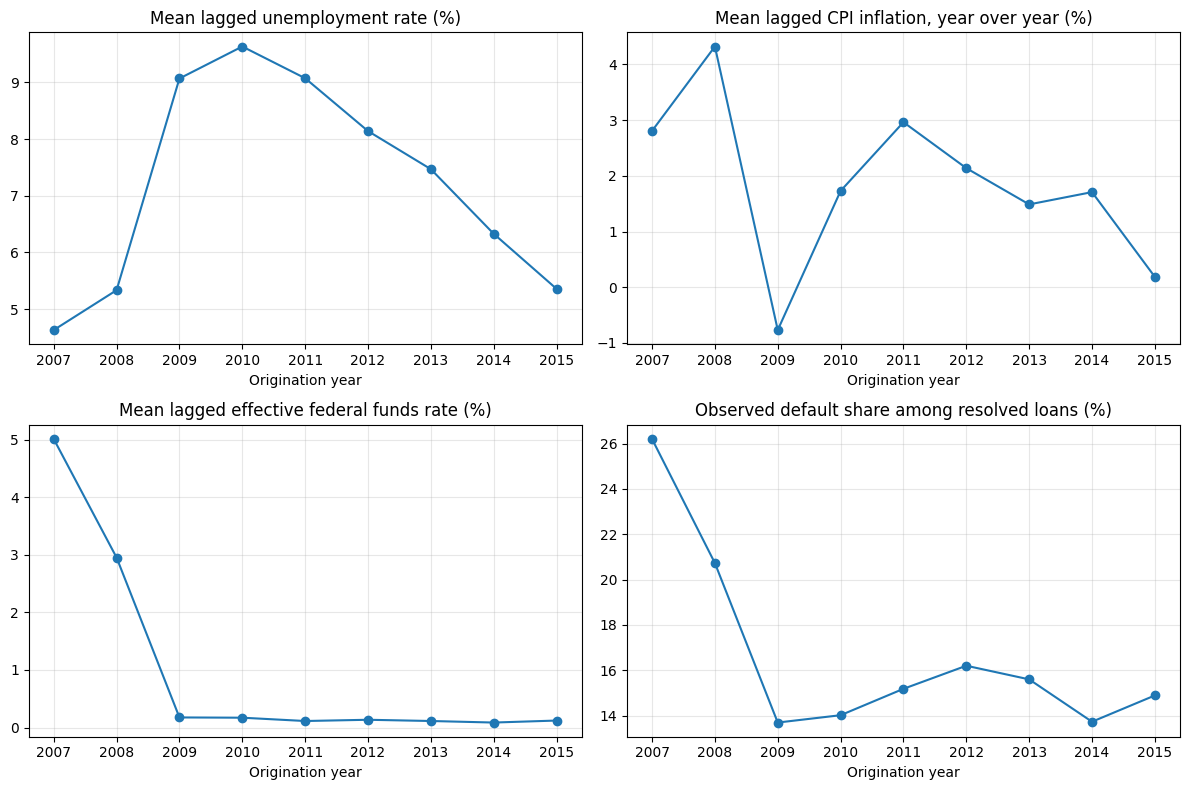

In [19]:
macro_year_profile = (
    df_macro.groupby("issue_year")
    .agg(
        loans=("default", "size"),
        observed_default_rate=("default", "mean"),
        unemployment_rate=("macro_unrate_pct", "mean"),
        unemployment_3m_change=("macro_unrate_change_3m_pp", "mean"),
        cpi_yoy_inflation=("macro_cpi_yoy_pct", "mean"),
        federal_funds_rate=("macro_fedfunds_pct", "mean"),
    )
    .reset_index()
    .sort_values("issue_year")
)

display(macro_year_profile.round(4))
macro_year_profile.to_csv(OUTPUT_DIR / "macro_profile_by_origination_year.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_specs = [
    ("unemployment_rate", "Mean lagged unemployment rate (%)"),
    ("cpi_yoy_inflation", "Mean lagged CPI inflation, year over year (%)"),
    ("federal_funds_rate", "Mean lagged effective federal funds rate (%)"),
    ("observed_default_rate", "Observed default share among resolved loans (%)"),
]
for ax, (column, title) in zip(axes.flat, plot_specs):
    values = macro_year_profile[column] * (100 if column == "observed_default_rate" else 1)
    ax.plot(macro_year_profile["issue_year"], values, marker="o")
    ax.set_title(title)
    ax.set_xlabel("Origination year")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Define identical baseline and macro-enhanced predictor sets

The baseline includes the same loan/borrower predictors used in Notebook 3, plus origination year and quarter. The macro condition adds only the five pre-defined macro features. `_source_row_id`, dates, the target and any post-outcome fields are never predictors.

In [20]:
TARGET_COLUMN = "default"
METADATA_COLUMNS = ["issue_date", "issue_month", "issue_year", "issue_quarter", "macro_available_month"]
IDENTIFIER_COLUMNS = {
    "id", "loan_id", "member_id", "_source_row_id", "url", "zip_code", "zipcode", "desc", "title"
}
FORBIDDEN_TOKENS = [
    "total_pymnt", "total_rec", "recoveries", "collection_recovery_fee",
    "last_pymnt", "last_credit_pull", "out_prncp", "hardship", "settlement",
    "debt_settlement", "loan_status", "next_pymnt",
]

leakage_columns = [
    col for col in df_macro.columns
    if any(token in col.lower() for token in FORBIDDEN_TOKENS)
]
if leakage_columns:
    raise ValueError(f"Potential post-outcome / leakage columns found: {leakage_columns}")

# mort_acc is completely missing in the training block of the first chronological folds.
# Exclude it from BOTH feature conditions so each fold uses the same predictor definition.
CONSISTENT_FEATURE_EXCLUSIONS = {"mort_acc"}
BASE_FEATURES = [
    col for col in df_macro.columns
    if col not in METADATA_COLUMNS + [TARGET_COLUMN] + MACRO_FEATURES
    and col.lower() not in IDENTIFIER_COLUMNS
    and col.lower() not in CONSISTENT_FEATURE_EXCLUSIONS
]
REMOVED_INCONSISTENT_FEATURES = sorted(
    col for col in df_macro.columns if col.lower() in CONSISTENT_FEATURE_EXCLUSIONS
)
if not BASE_FEATURES:
    raise ValueError("No baseline predictor columns remain.")

print("Baseline loan/borrower predictors:", len(BASE_FEATURES))
print("Excluded consistently due to unavailable early-fold values:", REMOVED_INCONSISTENT_FEATURES)
print("Additional origination-time predictors: issue_year, issue_quarter")
print("Additional macro predictors:", MACRO_FEATURES)
print("Leakage audit: no forbidden post-outcome fields found.")
print("Prediction timing: origination, after underwriting grade/rate assignment.")


Baseline loan/borrower predictors: 24
Excluded consistently due to unavailable early-fold values: ['mort_acc']
Additional origination-time predictors: issue_year, issue_quarter
Additional macro predictors: ['macro_unrate_pct', 'macro_unrate_change_3m_pp', 'macro_cpi_yoy_pct', 'macro_fedfunds_pct', 'macro_fedfunds_change_3m_pp']
Leakage audit: no forbidden post-outcome fields found.
Prediction timing: origination, after underwriting grade/rate assignment.


## 7. Build the same expanding-window pooled folds as Notebook 3

For each test year *t*:

- Training: all eligible loans issued before year *t − 1*.
- Validation: loans issued in year *t − 1*.
- Test: loans issued in year *t*.

Both feature conditions use exactly the same row indices in every fold.

In [21]:
def class_counts(series):
    counts = series.value_counts().to_dict()
    return int(counts.get(0, 0)), int(counts.get(1, 0))

fold_records = []
for test_year in TEST_YEARS:
    validation_year = test_year - 1
    train = df_macro.loc[df_macro["issue_year"] < validation_year]
    validation = df_macro.loc[df_macro["issue_year"] == validation_year]
    test = df_macro.loc[df_macro["issue_year"] == test_year]
    train_0, train_1 = class_counts(train[TARGET_COLUMN]) if len(train) else (0, 0)
    val_0, val_1 = class_counts(validation[TARGET_COLUMN]) if len(validation) else (0, 0)
    test_0, test_1 = class_counts(test[TARGET_COLUMN]) if len(test) else (0, 0)

    reasons = []
    if len(train) < MIN_TRAIN_ROWS:
        reasons.append(f"training rows < {MIN_TRAIN_ROWS}")
    if min(train_0, train_1) < MIN_TRAIN_PER_CLASS:
        reasons.append(f"training class count < {MIN_TRAIN_PER_CLASS}")
    if len(validation) < MIN_VALIDATION_ROWS:
        reasons.append(f"validation rows < {MIN_VALIDATION_ROWS}")
    if min(val_0, val_1) < MIN_VALIDATION_TEST_PER_CLASS:
        reasons.append(f"validation class count < {MIN_VALIDATION_TEST_PER_CLASS}")
    if len(test) < MIN_TEST_ROWS:
        reasons.append(f"test rows < {MIN_TEST_ROWS}")
    if min(test_0, test_1) < MIN_VALIDATION_TEST_PER_CLASS:
        reasons.append(f"test class count < {MIN_VALIDATION_TEST_PER_CLASS}")

    fold_records.append({
        "train_years": f"{int(train['issue_year'].min())}–{validation_year - 1}" if len(train) else "none",
        "validation_year": validation_year,
        "test_year": test_year,
        "train_rows": len(train),
        "train_defaults": train_1,
        "validation_rows": len(validation),
        "validation_defaults": val_1,
        "test_rows": len(test),
        "test_defaults": test_1,
        "status": "run" if not reasons else "skip",
        "reason": "; ".join(reasons),
    })

fold_plan = pd.DataFrame(fold_records)
display(fold_plan)
fold_plan.to_csv(OUTPUT_DIR / "macro_temporal_fold_plan.csv", index=False)
if not (fold_plan["status"] == "run").any():
    raise ValueError("No eligible macro experiment folds were found.")

,train_years,validation_year,test_year,train_rows,train_defaults,validation_rows,validation_defaults,test_rows,test_defaults,status,reason
0,2007–2010,2011,2012,20814,3134,21721,3297,53367,8644,run,
1,2007–2011,2012,2013,42535,6431,53367,8644,134804,21024,run,
2,2007–2012,2013,2014,95902,15075,134804,21024,162570,22315,run,
3,2007–2013,2014,2015,230706,36099,162570,22315,283026,42132,run,


## 8. Build leakage-safe preprocessing and candidate models

All imputers, scaling and one-hot encoding are fitted on each fold's training records only. The same two candidate algorithms are available under both feature conditions. The macro comparison therefore changes the feature block, not the model menu or test periods.

In [22]:
def make_one_hot_encoder(dense=False):
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=not dense)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=not dense)


def prepare_feature_frame(frame, include_macro=False):
    X = frame[BASE_FEATURES].copy()
    if "term" in X.columns:
        X["term"] = X["term"].astype("Int64").astype("string").astype(object)
    # Include origination time in BOTH conditions so the comparison isolates the macro block.
    X["issue_year"] = frame["issue_year"].astype(float).to_numpy()
    X["issue_quarter"] = frame["issue_quarter"].astype("string").astype(object).to_numpy()
    if include_macro:
        for column in MACRO_FEATURES:
            X[column] = frame[column].astype(float).to_numpy()
    numeric_columns = X.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_columns = [col for col in X.columns if col not in numeric_columns]
    for col in categorical_columns:
        X[col] = X[col].astype(object)
    return X


def build_preprocessor(X_train, dense=False, scale_numeric=True):
    numeric_columns = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_columns = [col for col in X_train.columns if col not in numeric_columns]
    transformers = []
    if numeric_columns:
        numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
        if scale_numeric:
            numeric_steps.append(("scaler", StandardScaler()))
        transformers.append(("numeric", Pipeline(numeric_steps), numeric_columns))
    if categorical_columns:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot_encoder(dense=dense)),
        ])
        transformers.append(("categorical", categorical_pipeline, categorical_columns))
    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0 if dense else 0.3,
    )


def build_candidate(model_name, X_train):
    if model_name == "Logistic Regression":
        preprocessor = build_preprocessor(X_train, dense=False, scale_numeric=True)
        classifier = LogisticRegression(
            max_iter=2500,
            class_weight="balanced",
            solver="lbfgs",
            random_state=RANDOM_STATE,
        )
    elif model_name == "Histogram Gradient Boosting":
        preprocessor = build_preprocessor(X_train, dense=True, scale_numeric=False)
        classifier = HistGradientBoostingClassifier(
            max_iter=80,
            learning_rate=0.06,
            max_leaf_nodes=15,
            min_samples_leaf=50,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        )
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return Pipeline([("preprocess", preprocessor), ("classifier", classifier)])


def calculate_metrics(y_true, probabilities, threshold=0.50, train_prevalence=None):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = (probabilities >= threshold).astype(int)
    result = {
        "threshold": float(threshold),
        "rows": int(len(y_true)),
        "actual_default_rate": float(y_true.mean()),
        "predicted_default_rate": float(predictions.mean()),
        "accuracy": accuracy_score(y_true, predictions),
        "default_precision": precision_score(y_true, predictions, zero_division=0),
        "default_recall": recall_score(y_true, predictions, zero_division=0),
        "default_f1": f1_score(y_true, predictions, zero_division=0),
        "average_precision": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan,
        "brier_score": brier_score_loss(y_true, probabilities),
    }
    if train_prevalence is not None:
        baseline_prob = np.full(len(y_true), float(train_prevalence))
        result["train_prevalence_brier_baseline"] = brier_score_loss(y_true, baseline_prob)
    return result

print("Candidate models and preprocessing functions are ready.")

Candidate models and preprocessing functions are ready.


## 9. Fit paired baseline and macro-enhanced models

Within every chronological fold:

1. Fit each candidate on the historical training block.
2. Choose the candidate with the highest validation average precision.
3. Refit/calibrate the selected candidate using training data only (two-fold sigmoid calibration).
4. Evaluate once on the untouched test year.

The test threshold is fixed at 0.50 for both conditions. This keeps the feature comparison focused on probability quality and ranking rather than selecting separate recall-driven operating points.

In [23]:
MODEL_NAMES = ["Logistic Regression", "Histogram Gradient Boosting"]
CONDITIONS = {
    "Baseline": False,
    "Baseline + macro": True,
}
TARGET_DEFAULT_RECALL = 0.70


def select_threshold_for_target_recall(y_validation, validation_probabilities, target_recall=0.70):
    """Choose a threshold using validation data only.

    Among thresholds achieving at least the requested validation recall, choose
    the one with highest precision. If no threshold reaches the requested recall,
    fall back to the threshold with the best validation F1.
    """
    precision, recall, thresholds = precision_recall_curve(
        np.asarray(y_validation, dtype=int),
        np.asarray(validation_probabilities, dtype=float),
    )
    if len(thresholds) == 0:
        return 0.50, np.nan, np.nan, "fallback_050_no_thresholds"

    feasible = np.flatnonzero(recall[:-1] >= target_recall)
    if len(feasible):
        best_precision = np.nanmax(precision[feasible])
        tied = feasible[np.isclose(precision[feasible], best_precision)]
        best_idx = int(tied[-1])  # highest threshold among equal-precision choices
        return (
            float(thresholds[best_idx]),
            float(precision[best_idx]),
            float(recall[best_idx]),
            "max_precision_at_or_above_target_recall",
        )

    f1_values = np.divide(
        2 * precision[:-1] * recall[:-1],
        precision[:-1] + recall[:-1],
        out=np.zeros_like(precision[:-1]),
        where=(precision[:-1] + recall[:-1]) > 0,
    )
    best_idx = int(np.nanargmax(f1_values))
    return (
        float(thresholds[best_idx]),
        float(precision[best_idx]),
        float(recall[best_idx]),
        "fallback_best_validation_f1_target_unreachable",
    )


validation_records = []
selected_fold_records = []
prediction_frames = []

for fold in fold_plan.loc[fold_plan["status"] == "run"].itertuples(index=False):
    test_year = int(fold.test_year)
    validation_year = int(fold.validation_year)
    train = df_macro.loc[df_macro["issue_year"] < validation_year].copy()
    validation = df_macro.loc[df_macro["issue_year"] == validation_year].copy()
    test = df_macro.loc[df_macro["issue_year"] == test_year].copy()

    y_train = train[TARGET_COLUMN].astype(int)
    y_validation = validation[TARGET_COLUMN].astype(int)
    y_test = test[TARGET_COLUMN].astype(int)
    train_prevalence = float(y_train.mean())

    print(f"\n===== Validation {validation_year} | Test {test_year} =====")

    for condition_name, include_macro in CONDITIONS.items():
        print(f"\nCondition: {condition_name}")
        X_train = prepare_feature_frame(train, include_macro=include_macro)
        X_validation = prepare_feature_frame(validation, include_macro=include_macro)
        X_test = prepare_feature_frame(test, include_macro=include_macro)

        validation_scores = {}
        for model_name in MODEL_NAMES:
            candidate = build_candidate(model_name, X_train)
            candidate.fit(X_train, y_train)
            validation_probabilities = candidate.predict_proba(X_validation)[:, 1]
            val_ap = average_precision_score(y_validation, validation_probabilities)
            val_auc = roc_auc_score(y_validation, validation_probabilities)
            validation_scores[model_name] = val_ap
            validation_records.append({
                "condition": condition_name,
                "test_year": test_year,
                "validation_year": validation_year,
                "model": model_name,
                "validation_average_precision": val_ap,
                "validation_roc_auc": val_auc,
                "validation_brier_score": brier_score_loss(y_validation, validation_probabilities),
            })
            print(f"  {model_name}: validation AP={val_ap:.4f}, ROC-AUC={val_auc:.4f}")
            del candidate, validation_probabilities
            gc.collect()

        selected_model_name = max(validation_scores, key=validation_scores.get)
        selected_template = build_candidate(selected_model_name, X_train)
        min_class_count = int(y_train.value_counts().min())
        n_calibration_folds = min(CALIBRATION_FOLDS, min_class_count)
        calibration_status = "sigmoid calibration on training data"

        calibrated_model = None
        if n_calibration_folds >= 2:
            calibration_cv = StratifiedKFold(
                n_splits=n_calibration_folds,
                shuffle=True,
                random_state=RANDOM_STATE,
            )
            try:
                try:
                    calibrated_model = CalibratedClassifierCV(
                        estimator=clone(selected_template),
                        method="sigmoid",
                        cv=calibration_cv,
                        n_jobs=N_JOBS,
                    )
                except TypeError:
                    calibrated_model = CalibratedClassifierCV(
                        base_estimator=clone(selected_template),
                        method="sigmoid",
                        cv=calibration_cv,
                        n_jobs=N_JOBS,
                    )
                calibrated_model.fit(X_train, y_train)
            except Exception as exc:
                calibrated_model = None
                calibration_status = f"uncalibrated fallback: {type(exc).__name__}"
        else:
            calibration_status = "uncalibrated fallback: insufficient training class count"

        if calibrated_model is not None:
            validation_final_probabilities = calibrated_model.predict_proba(X_validation)[:, 1]
            test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]
        else:
            fallback_model = build_candidate(selected_model_name, X_train)
            fallback_model.fit(X_train, y_train)
            validation_final_probabilities = fallback_model.predict_proba(X_validation)[:, 1]
            test_probabilities = fallback_model.predict_proba(X_test)[:, 1]
            del fallback_model

        # Threshold is selected on calibrated validation probabilities, never test labels.
        selected_threshold, validation_precision_at_threshold, validation_recall_at_threshold, threshold_method = (
            select_threshold_for_target_recall(
                y_validation,
                validation_final_probabilities,
                target_recall=TARGET_DEFAULT_RECALL,
            )
        )

        metrics_050 = calculate_metrics(
            y_test,
            test_probabilities,
            threshold=0.50,
            train_prevalence=train_prevalence,
        )
        metrics_target_recall = calculate_metrics(
            y_test,
            test_probabilities,
            threshold=selected_threshold,
            train_prevalence=train_prevalence,
        )
        selected_fold_records.append({
            "condition": condition_name,
            "test_year": test_year,
            "validation_year": validation_year,
            "selected_model": selected_model_name,
            "validation_average_precision": validation_scores[selected_model_name],
            "calibration": calibration_status,
            "target_validation_recall": TARGET_DEFAULT_RECALL,
            "threshold_selection_method": threshold_method,
            "threshold_selected_on_validation": selected_threshold,
            "validation_precision_at_selected_threshold": validation_precision_at_threshold,
            "validation_recall_at_selected_threshold": validation_recall_at_threshold,
            **{f"test_{key}_at_050": value for key, value in metrics_050.items()},
            **{f"test_{key}_at_target_recall": value for key, value in metrics_target_recall.items()},
        })

        metadata = test[["issue_year", "issue_quarter", "term", "grade", "purpose"]].copy().reset_index(drop=True)
        metadata["condition"] = condition_name
        metadata["test_year"] = test_year
        metadata["actual_default"] = y_test.reset_index(drop=True).to_numpy()
        metadata["predicted_probability"] = test_probabilities
        metadata["threshold_selected_on_validation"] = selected_threshold
        metadata["predicted_default_at_050"] = (test_probabilities >= 0.50).astype(int)
        metadata["predicted_default_at_target_recall"] = (test_probabilities >= selected_threshold).astype(int)
        metadata["selected_model"] = selected_model_name
        prediction_frames.append(metadata)

        print(
            f"  Selected: {selected_model_name}; calibration={calibration_status}; "
            f"validation threshold={selected_threshold:.4f}; "
            f"validation recall={validation_recall_at_threshold:.3f}; "
            f"test AP={metrics_050['average_precision']:.4f}; "
            f"test ROC-AUC={metrics_050['roc_auc']:.4f}; "
            f"test recall at selected threshold={metrics_target_recall['default_recall']:.3f}"
        )

        del X_train, X_validation, X_test, selected_template, calibrated_model
        del validation_final_probabilities, test_probabilities
        gc.collect()

    del train, validation, test, y_train, y_validation, y_test
    gc.collect()

validation_results = pd.DataFrame(validation_records)
selected_fold_results = pd.DataFrame(selected_fold_records)
out_of_time_predictions = pd.concat(prediction_frames, ignore_index=True)

if validation_results.empty or selected_fold_results.empty or out_of_time_predictions.empty:
    raise ValueError("No macro experiment results were produced. Review the fold plan and data.")

print("\nValidation comparison")
display(validation_results.sort_values(["condition", "test_year", "validation_average_precision"], ascending=[True, True, False]).round(4))
print("\nSelected-model test metrics by fold")
display(selected_fold_results.round(4))



===== Validation 2011 | Test 2012 =====

Condition: Baseline
  Logistic Regression: validation AP=0.2807, ROC-AUC=0.6997
  Histogram Gradient Boosting: validation AP=0.2864, ROC-AUC=0.7032
  Selected: Histogram Gradient Boosting; calibration=sigmoid calibration on training data; validation threshold=0.1347; validation recall=0.702; test AP=0.2806; test ROC-AUC=0.6727; test recall at selected threshold=0.663

Condition: Baseline + macro
  Logistic Regression: validation AP=0.2810, ROC-AUC=0.6996
  Histogram Gradient Boosting: validation AP=0.2849, ROC-AUC=0.7010
  Selected: Histogram Gradient Boosting; calibration=sigmoid calibration on training data; validation threshold=0.1346; validation recall=0.700; test AP=0.2801; test ROC-AUC=0.6713; test recall at selected threshold=0.662

===== Validation 2012 | Test 2013 =====

Condition: Baseline
  Logistic Regression: validation AP=0.2845, ROC-AUC=0.6783
  Histogram Gradient Boosting: validation AP=0.2860, ROC-AUC=0.6774
  Selected: Histogr

,condition,test_year,validation_year,model,validation_average_precision,validation_roc_auc,validation_brier_score
1,Baseline,2012,2011,Histogram Gradient Boosting,0.2864,0.7032,0.1200
0,Baseline,2012,2011,Logistic Regression,0.2807,0.6997,0.1843
5,Baseline,2013,2012,Histogram Gradient Boosting,0.2860,0.6774,0.1281
4,Baseline,2013,2012,Logistic Regression,0.2845,0.6783,0.2204
9,Baseline,2014,2013,Histogram Gradient Boosting,0.2772,0.6870,0.1242
8,Baseline,2014,2013,Logistic Regression,0.2740,0.6847,0.2475
13,Baseline,2015,2014,Histogram Gradient Boosting,0.2359,0.6744,0.1135
12,Baseline,2015,2014,Logistic Regression,0.2331,0.6726,0.1778
3,Baseline + macro,2012,2011,Histogram Gradient Boosting,0.2849,0.7010,0.1202
2,Baseline + macro,2012,2011,Logistic Regression,0.2810,0.6996,0.1964



Selected-model test metrics by fold


,condition,test_year,validation_year,selected_model,validation_average_precision,calibration,target_validation_recall,threshold_selection_method,threshold_selected_on_validation,validation_precision_at_selected_threshold,...,test_actual_default_rate_at_target_recall,test_predicted_default_rate_at_target_recall,test_accuracy_at_target_recall,test_default_precision_at_target_recall,test_default_recall_at_target_recall,test_default_f1_at_target_recall,test_average_precision_at_target_recall,test_roc_auc_at_target_recall,test_brier_score_at_target_recall,test_train_prevalence_brier_baseline_at_target_recall
0,Baseline,2012,2011,Histogram Gradient Boosting,0.2864,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1347,0.2385,...,0.1620,0.4607,0.5922,0.2332,0.6632,0.3451,0.2806,0.6727,0.1287,0.1359
1,Baseline + macro,2012,2011,Histogram Gradient Boosting,0.2849,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1346,0.2388,...,0.1620,0.4592,0.5932,0.2334,0.6617,0.3451,0.2801,0.6713,0.1288,0.1359
2,Baseline,2013,2012,Histogram Gradient Boosting,0.2860,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1407,0.2330,...,0.1560,0.5494,0.5335,0.2174,0.7658,0.3387,0.2705,0.6822,0.1247,0.1317
3,Baseline + macro,2013,2012,Histogram Gradient Boosting,0.2848,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1387,0.2311,...,0.1560,0.5606,0.5253,0.2157,0.7753,0.3375,0.2714,0.6822,0.1246,0.1317
4,Baseline,2014,2013,Histogram Gradient Boosting,0.2772,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1633,0.2302,...,0.1373,0.3070,0.6914,0.2210,0.4941,0.3054,0.2234,0.6643,0.1138,0.1188
5,Baseline + macro,2014,2013,Histogram Gradient Boosting,0.2781,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1612,0.2302,...,0.1373,0.3416,0.6685,0.2157,0.5368,0.3078,0.2239,0.6645,0.1138,0.1188
6,Baseline,2015,2014,Histogram Gradient Boosting,0.2359,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1084,0.1985,...,0.1489,0.4027,0.6352,0.2319,0.6272,0.3386,0.2600,0.6835,0.1220,0.1268
7,Baseline + macro,2015,2014,Histogram Gradient Boosting,0.2366,sigmoid calibration on training data,0.7,max_precision_at_or_above_target_recall,0.1202,0.2001,...,0.1489,0.4516,0.6027,0.2249,0.6823,0.3383,0.2605,0.6854,0.1208,0.1268


## 10. Paired incremental-value and threshold-policy comparison

The paired comparison uses identical test loans for the baseline and macro-enhanced conditions. Ranking and probability metrics are evaluated independently of classification thresholds.

Two classification policies are reported:

1. **Fixed 0.50 threshold:** retained as a conventional diagnostic. In the prior executed run, this threshold classified almost no loans as defaults, so its recall was nearly zero.
2. **Validation-selected threshold:** for each fold and feature condition, the notebook chooses the threshold on calibrated validation probabilities that gives at least 70% recall with the highest precision. If that target is unattainable, it falls back to the best validation F1 threshold. The chosen threshold is then applied unchanged to the test fold.

Do not choose a threshold from test results. A 70% recall target is an illustrative screening policy, not an economically validated lending rule. A cost matrix should be agreed with the project stakeholder before describing it as a business-optimal threshold.


In [24]:
comparison_columns = [
    "test_rows_at_050", "test_actual_default_rate_at_050",
    "test_predicted_default_rate_at_050", "test_default_precision_at_050",
    "test_default_recall_at_050", "test_default_f1_at_050",
    "test_average_precision_at_050", "test_roc_auc_at_050", "test_brier_score_at_050",
    "threshold_selected_on_validation", "validation_recall_at_selected_threshold",
    "test_predicted_default_rate_at_target_recall", "test_default_precision_at_target_recall",
    "test_default_recall_at_target_recall", "test_default_f1_at_target_recall",
    "selected_model", "calibration", "threshold_selection_method",
]
wide = selected_fold_results.pivot(index="test_year", columns="condition", values=comparison_columns)
wide.columns = [f"{metric}__{condition}" for metric, condition in wide.columns]
wide = wide.reset_index()

for metric in ["test_average_precision_at_050", "test_roc_auc_at_050", "test_brier_score_at_050"]:
    baseline_col = f"{metric}__Baseline"
    macro_col = f"{metric}__Baseline + macro"
    if baseline_col in wide.columns and macro_col in wide.columns:
        wide[f"delta_{metric}"] = wide[macro_col] - wide[baseline_col]

print("Paired results by test year")
display(wide.round(4))
wide.to_csv(OUTPUT_DIR / "macro_incremental_comparison_by_fold.csv", index=False)

aggregate_rows = []
for condition_name, group in out_of_time_predictions.groupby("condition"):
    y_true = group["actual_default"].astype(int).to_numpy()
    probabilities = group["predicted_probability"].astype(float).to_numpy()
    predictions_050 = (probabilities >= 0.50).astype(int)
    selected_thresholds = group["threshold_selected_on_validation"].astype(float).to_numpy()
    predictions_target_recall = (probabilities >= selected_thresholds).astype(int)
    aggregate_rows.append({
        "condition": condition_name,
        "folds": int(group["test_year"].nunique()),
        "rows": len(group),
        "actual_default_rate": float(y_true.mean()),
        "predicted_default_rate_at_050": float(predictions_050.mean()),
        "default_precision_at_050": precision_score(y_true, predictions_050, zero_division=0),
        "default_recall_at_050": recall_score(y_true, predictions_050, zero_division=0),
        "default_f1_at_050": f1_score(y_true, predictions_050, zero_division=0),
        "predicted_default_rate_at_target_recall": float(predictions_target_recall.mean()),
        "default_precision_at_target_recall": precision_score(y_true, predictions_target_recall, zero_division=0),
        "default_recall_at_target_recall": recall_score(y_true, predictions_target_recall, zero_division=0),
        "default_f1_at_target_recall": f1_score(y_true, predictions_target_recall, zero_division=0),
        "average_precision": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "brier_score": brier_score_loss(y_true, probabilities),
    })
aggregate_comparison = pd.DataFrame(aggregate_rows)
display(aggregate_comparison.round(4))
aggregate_comparison.to_csv(OUTPUT_DIR / "macro_incremental_comparison_aggregate.csv", index=False)

threshold_policy = selected_fold_results[[
    "condition", "test_year", "validation_year", "selected_model",
    "target_validation_recall", "threshold_selection_method",
    "threshold_selected_on_validation", "validation_precision_at_selected_threshold",
    "validation_recall_at_selected_threshold",
    "test_default_precision_at_target_recall", "test_default_recall_at_target_recall",
    "test_predicted_default_rate_at_target_recall",
]].copy()
threshold_policy.to_csv(OUTPUT_DIR / "macro_threshold_policy_by_fold.csv", index=False)


Paired results by test year


,test_year,test_rows_at_050__Baseline,test_rows_at_050__Baseline + macro,test_actual_default_rate_at_050__Baseline,test_actual_default_rate_at_050__Baseline + macro,test_predicted_default_rate_at_050__Baseline,test_predicted_default_rate_at_050__Baseline + macro,test_default_precision_at_050__Baseline,test_default_precision_at_050__Baseline + macro,test_default_recall_at_050__Baseline,...,test_default_f1_at_target_recall__Baseline + macro,selected_model__Baseline,selected_model__Baseline + macro,calibration__Baseline,calibration__Baseline + macro,threshold_selection_method__Baseline,threshold_selection_method__Baseline + macro,delta_test_average_precision_at_050,delta_test_roc_auc_at_050,delta_test_brier_score_at_050
0,2012,53367,53367,0.161973,0.161973,0.000337,0.000281,0.5,0.6,0.001041,...,0.345077,Histogram Gradient Boosting,Histogram Gradient Boosting,sigmoid calibration on training data,sigmoid calibration on training data,max_precision_at_or_above_target_recall,max_precision_at_or_above_target_recall,-0.000517,-0.00137,0.000105
1,2013,134804,134804,0.15596,0.15596,0.000853,0.000504,0.46087,0.470588,0.002521,...,0.337467,Histogram Gradient Boosting,Histogram Gradient Boosting,sigmoid calibration on training data,sigmoid calibration on training data,max_precision_at_or_above_target_recall,max_precision_at_or_above_target_recall,0.000896,0.000006,-0.000099
2,2014,162570,162570,0.137264,0.137264,0.000006,0.000006,0.0,0.0,0.0,...,0.307765,Histogram Gradient Boosting,Histogram Gradient Boosting,sigmoid calibration on training data,sigmoid calibration on training data,max_precision_at_or_above_target_recall,max_precision_at_or_above_target_recall,0.000461,0.000107,-0.00005
3,2015,283026,283026,0.148863,0.148863,0.0,0.0,0.0,0.0,0.0,...,0.338306,Histogram Gradient Boosting,Histogram Gradient Boosting,sigmoid calibration on training data,sigmoid calibration on training data,max_precision_at_or_above_target_recall,max_precision_at_or_above_target_recall,0.000505,0.001854,-0.001177


,condition,folds,rows,actual_default_rate,predicted_default_rate_at_050,default_precision_at_050,default_recall_at_050,default_f1_at_050,predicted_default_rate_at_target_recall,default_precision_at_target_recall,default_recall_at_target_recall,default_f1_at_target_recall,average_precision,roc_auc,brier_score
0,Baseline,4,633767,0.1485,0.0002,0.4627,0.0007,0.0013,0.4142,0.2258,0.6299,0.3325,0.2487,0.6702,0.1210
1,Baseline + macro,4,633767,0.1485,0.0001,0.4881,0.0004,0.0009,0.4472,0.2214,0.6667,0.3324,0.2519,0.6744,0.1205


## 11. Calibration and vintage diagnostics

Calibration plots use held-out test predictions only for evaluation. Test labels are not used to refit the calibrator, choose models or select thresholds.


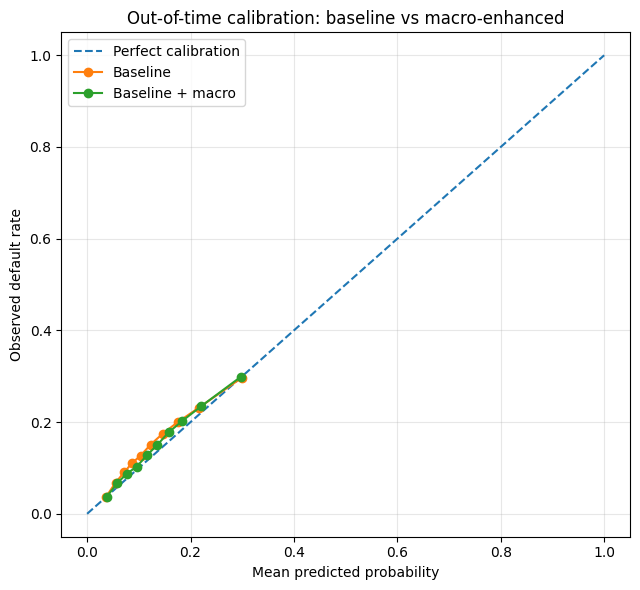

,probability_bin,rows,mean_predicted_probability,observed_default_rate,condition
0,0,63377,0.0363,0.0366,Baseline
1,1,63377,0.0551,0.0681,Baseline
2,2,63376,0.0715,0.0903,Baseline
3,3,63377,0.0869,0.1107,Baseline
4,4,63377,0.1034,0.1268,Baseline
5,5,63376,0.1228,0.1509,Baseline
6,6,63377,0.1460,0.1745,Baseline
7,7,63376,0.1750,0.1997,Baseline
8,8,63377,0.2156,0.2310,Baseline
9,9,63377,0.2988,0.2965,Baseline


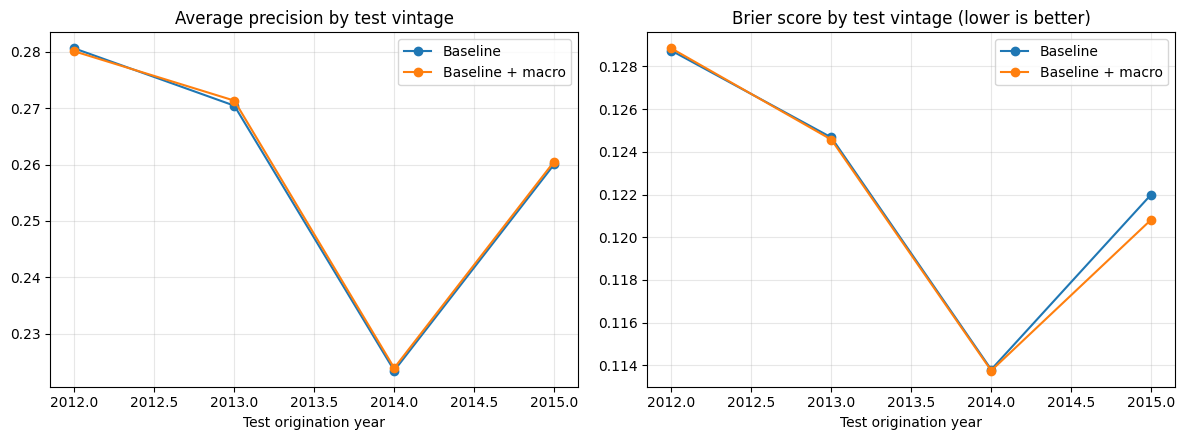

In [25]:
calibration_rows = []
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

for condition_name, group in out_of_time_predictions.groupby("condition"):
    calibration_frame = group[["actual_default", "predicted_probability"]].copy()
    calibration_frame["probability_bin"] = pd.qcut(
        calibration_frame["predicted_probability"],
        q=10,
        labels=False,
        duplicates="drop",
    )
    bins = (
        calibration_frame.groupby("probability_bin", observed=True)
        .agg(
            rows=("actual_default", "size"),
            mean_predicted_probability=("predicted_probability", "mean"),
            observed_default_rate=("actual_default", "mean"),
        )
        .reset_index()
    )
    bins["condition"] = condition_name
    calibration_rows.append(bins)
    ax.plot(
        bins["mean_predicted_probability"],
        bins["observed_default_rate"],
        marker="o",
        label=condition_name,
    )

ax.set_title("Out-of-time calibration: baseline vs macro-enhanced")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed default rate")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

calibration_bins = pd.concat(calibration_rows, ignore_index=True)
display(calibration_bins.round(4))
calibration_bins.to_csv(OUTPUT_DIR / "macro_calibration_bins.csv", index=False)

# Compare average precision and Brier score by test year.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for condition_name, group in out_of_time_predictions.groupby("condition"):
    yearly_rows = []
    for year, year_group in group.groupby("test_year"):
        y_true = year_group["actual_default"].astype(int).to_numpy()
        probs = year_group["predicted_probability"].astype(float).to_numpy()
        yearly_rows.append({
            "test_year": year,
            "average_precision": average_precision_score(y_true, probs),
            "brier_score": brier_score_loss(y_true, probs),
        })
    yearly = pd.DataFrame(yearly_rows).sort_values("test_year")
    axes[0].plot(yearly["test_year"], yearly["average_precision"], marker="o", label=condition_name)
    axes[1].plot(yearly["test_year"], yearly["brier_score"], marker="o", label=condition_name)
axes[0].set_title("Average precision by test vintage")
axes[1].set_title("Brier score by test vintage (lower is better)")
for ax in axes:
    ax.set_xlabel("Test origination year")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 12. Save the experiment outputs

The outputs include the threshold policy selected on each validation fold. This allows the fixed 0.50 diagnostic and the validation-selected recall policy to be compared separately.


In [26]:
validation_results.to_csv(OUTPUT_DIR / "macro_validation_model_comparison.csv", index=False)
selected_fold_results.to_csv(OUTPUT_DIR / "macro_selected_model_metrics_by_fold.csv", index=False)
out_of_time_predictions.to_csv(OUTPUT_DIR / "macro_out_of_time_predictions.csv", index=False)

expected_outputs = [
    "macro_temporal_fold_plan.csv",
    "macro_profile_by_origination_year.csv",
    "macro_validation_model_comparison.csv",
    "macro_selected_model_metrics_by_fold.csv",
    "macro_incremental_comparison_by_fold.csv",
    "macro_incremental_comparison_aggregate.csv",
    "macro_out_of_time_predictions.csv",
    "macro_calibration_bins.csv",
    "macro_threshold_policy_by_fold.csv",
]
output_inventory = pd.DataFrame({
    "file": expected_outputs,
    "created": [(OUTPUT_DIR / name).exists() for name in expected_outputs],
})
display(output_inventory)
print("Macro dataset:", MACRO_FEATURED_PATH)
print("FRED macro feature cache:", macro_monthly_path)
print("Notebook 4 complete. Outputs:", OUTPUT_DIR)

,file,created
0,macro_temporal_fold_plan.csv,True
1,macro_profile_by_origination_year.csv,True
2,macro_validation_model_comparison.csv,True
3,macro_selected_model_metrics_by_fold.csv,True
4,macro_incremental_comparison_by_fold.csv,True
5,macro_incremental_comparison_aggregate.csv,True
6,macro_out_of_time_predictions.csv,True
7,macro_calibration_bins.csv,True
8,macro_threshold_policy_by_fold.csv,True


Macro dataset: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\processed\featured_data_macro.csv
FRED macro feature cache: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\external\fred\macro_monthly_features.csv
Notebook 4 complete. Outputs: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\outputs


## 13. How to interpret the result

Use `macro_incremental_comparison_aggregate.csv` and `macro_incremental_comparison_by_fold.csv` as the main evidence.

- **Average precision increases:** macro features improved the ranking of defaulted loans over non-defaulted loans on the held-out vintages.
- **ROC-AUC increases:** macro features improved overall ranking/discrimination.
- **Brier score decreases:** macro features improved probability accuracy on the held-out vintages.
- **Improvement appears in only one year:** the result may be vintage-specific rather than robust.
- **No consistent improvement:** the existing borrower/loan attributes and origination-time variables may already capture most of the useful signal in these national monthly indicators.
- **Validation-selected recall threshold:** precision/recall on the test fold must be interpreted as an out-of-time evaluation of a policy chosen on validation data. It is not a universal optimum.

Do not interpret an improvement as a causal effect. Do not select the better feature condition by looking at the final test results and then report that same test result as an unbiased final estimate; the test results are for this pre-specified comparison. Any further tuning should use new validation data or another later holdout.

### Point-in-time limitation and future extension

For a stronger historical simulation, replace the current revised FRED histories with **ALFRED real-time vintages** so each origination month is paired with the macro values actually published at that time. That requires a point-in-time data retrieval workflow and may require an API credential. The present notebook deliberately records its use of revised historical series so the limitation remains visible.
